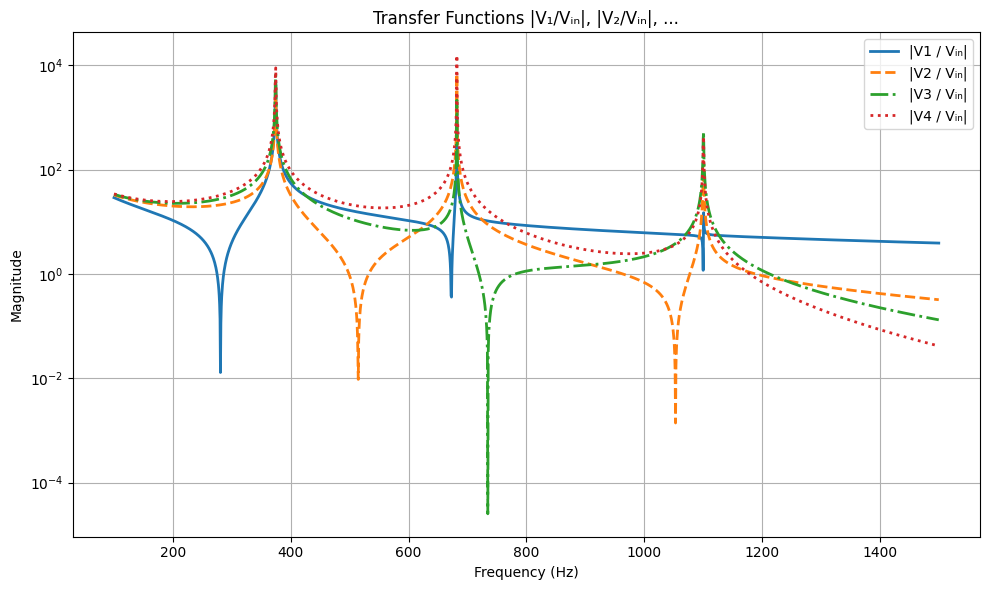

In [20]:
import numpy as np
import matplotlib.pyplot as plt

class LCCascadeResponse:
    def __init__(self, L_vals, C_vals):
        # Save component values
        self.L_vals = L_vals
        self.C_vals = C_vals
        self.n_stages = len(L_vals)
        if len(C_vals) != self.n_stages + 1:
            raise ValueError("C_vals must have one more element than L_vals (one capacitor per node).")
        self.H_vals = None
        self.frequencies = None

    def simulate(self, f_min=100, f_max=1500, points=2000):
        self.frequencies = np.linspace(f_min, f_max, points)
        omega = 2 * np.pi * self.frequencies
        s_vals = 1j * omega

        self.H_vals = np.zeros((self.n_stages, len(s_vals)), dtype=complex)

        for idx, s in enumerate(s_vals):
            N = self.n_stages + 1  # number of nodes from Vin to Vout
            Y = np.zeros((N, N), dtype=complex)

            # Ground capacitor at Vin (node 0)
            Y[0, 0] += s * self.C_vals[0]

            for k in range(self.n_stages):
                L = self.L_vals[k]
                C = self.C_vals[k + 1]

                # Inductor between node k and k+1
                Y[k, k]         += 1 / (s * L)
                Y[k, k + 1]     += -1 / (s * L)
                Y[k + 1, k]     += -1 / (s * L)
                Y[k + 1, k + 1] += 1 / (s * L)

                # Capacitor to ground at node k+1
                Y[k + 1, k + 1] += s * C

            # Inject current at Vin
            I = np.zeros(N, dtype=complex)
            I[0] = 1.0

            # Solve for node voltages
            V = np.linalg.solve(Y, I)

            # Save transfer functions from Vin to V1, V2, ..., Vout
            for k in range(self.n_stages):
                self.H_vals[k, idx] = V[k + 1]

    def plot(self):
        if self.H_vals is None or self.frequencies is None:
            raise RuntimeError("Call simulate() before plot().")

        plt.figure(figsize=(10, 6))
        labels = [f"|V{k+1} / Vᵢₙ|" for k in range(self.n_stages)]
        linestyles = ['-', '--', '-.', ':']

        for k in range(self.n_stages):
            plt.plot(self.frequencies, np.abs(self.H_vals[k]),
                     label=labels[k], linestyle=linestyles[k % len(linestyles)], linewidth=2)

        plt.yscale('log')
        plt.xlabel("Frequency (Hz)")
        plt.ylabel("Magnitude")
        plt.title("Transfer Functions |V₁/Vᵢₙ|, |V₂/Vᵢₙ|, ...")
        plt.grid(True)
        plt.legend()
        plt.tight_layout()
        plt.show()

# Example usage:
L_vals = [10e-3, 12e-3, 8e-3, 15e-3]  # Inductors: L0, L1, L2, L3
C_vals = [1e-12, 28.14e-6, 14.36e-6, 5.82e-6, 3.13e-6]  # Capacitors: C0 (Vin), C1 (V1), ..., C4 (Vout)

circuit = LCCascadeResponse(L_vals, C_vals)
circuit.simulate()
circuit.plot()
